In [1]:
## running with xcast_env

In [117]:
import xarray as xr
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as ticker
from matplotlib.ticker import Formatter, MaxNLocator
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm, Normalize
from matplotlib.gridspec import GridSpec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.colors as mcolors
import matplotlib.colorbar as mcolorbar

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.geoaxes import GeoAxes
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
import cartopy.io.shapereader as shpreader

from scipy.stats import percentileofscore
from scipy.ndimage import gaussian_filter


In [118]:
# lead week 1 [0, 7],week 2 [7, 14] week 34 [14, 28]
week = "Week1" #"Week34"
weekn =1
lead = (0, 7) 
sample_no = 8

In [119]:
test_model = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/IMD_Data_New/{week}/GEFS_pra_2022-2024.nc")['prcp']

In [120]:
test_model['S'][8]

<xarray.DataArray 'S' ()> Size: 8B
array('2022-07-30T00:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    S        datetime64[ns] 8B 2022-07-30
Attributes:
    long_name:      Start Time
    standard_name:  forecast_reference_time
    pointwidth:     0.0
    expires:        1739318400
    gridtype:       0

In [100]:
test_model

<xarray.DataArray 'prcp' (S: 54, M: 31, Y: 32, X: 31)> Size: 13MB
[1660608 values with dtype=float64]
Coordinates:
  * S        (S) datetime64[ns] 432B 2022-06-04 2022-06-11 ... 2024-09-28
  * X        (X) float32 124B 68.0 69.0 70.0 71.0 72.0 ... 95.0 96.0 97.0 98.0
  * M        (M) float32 124B 0.0 1.0 2.0 3.0 4.0 ... 26.0 27.0 28.0 29.0 30.0
  * Y        (Y) float32 128B 7.0 8.0 9.0 10.0 11.0 ... 34.0 35.0 36.0 37.0 38.0
Attributes:
    pointwidth:          0.0
    expires:             1739318400
    long_name:           Total Precipitation
    standard_name:       precipitation_flux
    level_type:          surface
    file_missing_value:  -9999.0
    history:             Averaged over L[1.0 days, 7.0 days] minimum 0.0% dat...
    units:               mm/day

In [121]:
test_model = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/IMD_Data_New/{week}/GEFS_pra_2022-2024.nc")['prcp']
t1 = test_model['S'] + pd.Timedelta(days=(lead[0] + lead[1]) / 2)
test_model = test_model.assign_coords(T=('S', t1.values)).swap_dims(S='T')

# IMD observstion data 
train_obs = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/IMD_Data_New/{week}/IMD_pra_1989-2010.nc")['prcp']
test_obs = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/IMD_Data_New/{week}/IMD_pra_2022-2024.nc")['prcp']


In [122]:
test_obs['T'][8]

<xarray.DataArray 'T' ()> Size: 8B
array('2022-08-02T12:00:00.000000000', dtype='datetime64[ns]')
Coordinates:
    T        datetime64[ns] 8B 2022-08-02T12:00:00
Attributes:
    standard_name:  time
    pointwidth:     7.0
    gridtype:       0

In [103]:
elr_probs = xr.open_dataset(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_prob_Week{weekn}_2022_2024.nc')['prcp']
qrf_prob =np.load(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/week_{weekn}_tuned_terciles_2022_2024.npy')

qrf_prob_rotated = np.transpose(qrf_prob, axes=(2, 3, 0, 1))
qrf_probs = xr.DataArray(
    qrf_prob_rotated,
    dims=elr_probs.dims,  # ('T', 'category', 'Y', 'X')
    coords=elr_probs.coords,
    name="qrf_probs"
)


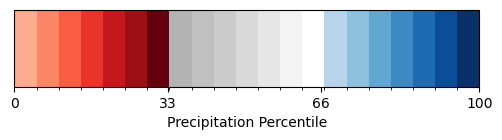

In [104]:
# Define 7 shades of each color
reds = plt.cm.Reds(np.linspace(0.3, 1, 7))
greens = plt.cm.gray(np.linspace(0.7, 1, 7))
blues = plt.cm.Blues(np.linspace(0.3, 1, 7))

# Stack them together: red → green → blue
colors = np.vstack([reds, greens, blues])

# Create the colormap
custom_cmap = mcolors.ListedColormap(colors, name='CustomPrecipPercentile')

# Show colorbar
fig, ax = plt.subplots(figsize=(6, 1))
norm = mcolors.BoundaryNorm(boundaries=np.linspace(0, 100, 22), ncolors=colors.shape[0])
cb = mcolorbar.ColorbarBase(ax, cmap=custom_cmap, norm=norm,
                            orientation='horizontal', ticks=[0, 33, 66, 100])
cb.set_label('Precipitation Percentile')
plt.show()


In [105]:
def compute_percentile_gridwise(train_data: xr.DataArray, test_data: xr.DataArray) -> xr.DataArray:
    """
    Compute percentile ranks of test_data using train_data as the reference distribution,
    for each grid point (Y, X). Handles NaNs in both training and test data.
    
    Parameters
    ----------
    train_data : xr.DataArray
        Historical data (T, Y, X)
    test_data : xr.DataArray
        Test data (T_test, Y, X)
        
    Returns
    -------
    test_percentiles : xr.DataArray
        Percentile values with same shape as test_data
    """
    # Create output array
    percentiles = np.full_like(test_data.values, fill_value=np.nan)

    T_test, Y, X = test_data.shape

    for i in range(Y):
        for j in range(X):
            # Extract and clean the reference distribution
            ref = train_data[:, i, j].values
            ref_clean = ref[~np.isnan(ref)]
            
            if len(ref_clean) < 5:  # Too few valid points — skip
                continue

            # Loop through test time steps
            for t in range(T_test):
                val = test_data[t, i, j].values
                if np.isnan(val):
                    continue  # leave as nan
                # Compute percentile
                pct = percentileofscore(ref_clean, val, kind='mean')
                percentiles[t, i, j] = pct

    return xr.DataArray(
        percentiles,
        coords=test_data.coords,
        dims=test_data.dims,
        name="precip_percentile"
    )



In [106]:
def create_custom_precip_colormap():
    reds = plt.cm.Reds(np.linspace(0.4, 1, 7))
    greens = plt.cm.Greens(np.linspace(0.4, 1, 7))
    blues = plt.cm.Blues(np.linspace(0.4, 1, 7))
    
    colors = np.vstack([reds, greens, blues])
    return mcolors.LinearSegmentedColormap.from_list("precip_percentile_cmap", colors)

custom_cmap = create_custom_precip_colormap()


In [107]:
def create_custom_precip_colormap_light():
    reds = plt.cm.Reds_r(np.linspace(0.1, 0.9, 7))
    greens = plt.cm.gray(np.linspace(0.6, 0.9, 7))
    blues = plt.cm.Blues(np.linspace(0.2, 0.65, 7))
    colors = np.vstack([reds, greens, blues])
    return mcolors.LinearSegmentedColormap.from_list("lighter_precip_percentile_cmap", colors)

custom_cmap = create_custom_precip_colormap_light()

In [108]:
def smooth_xarray_with_nan(data, sigma=1):
    nan_mask = np.isnan(data)
    filled_data = data.fillna(data.mean())
    smoothed = gaussian_filter(filled_data, sigma=sigma)
    smoothed_data = xr.DataArray(smoothed, coords=data.coords, dims=data.dims)
    smoothed_data = smoothed_data.where(~nan_mask)
    return smoothed_data

In [109]:
# Get percentile version of test data
test_percentiles = compute_percentile_gridwise(train_obs, test_obs)


In [110]:
mean_over_M = test_model.mean(dim='M', skipna=True)*86400
model_percentiles = compute_percentile_gridwise(train_obs, mean_over_M)


In [111]:
# Select the 13th sample (Python is 0-indexed → index 12)
data_13 = model_percentiles.isel(T=sample_no)
smdata_13 = smooth_xarray_with_nan(data_13, sigma=1)

obs_13 = test_percentiles.isel(T=sample_no)
smdata_13_obs = smooth_xarray_with_nan(obs_13, sigma=1)


In [112]:
import xarray as xr
import numpy as np

def process_terciles(terciles, sigma=1):
    """
    Processes a 3-category tercile probability array (e.g., from a QR forest),
    applies smoothing, normalization, and returns category-specific max masks.

    Parameters:
    -----------
    terciles : xarray.DataArray
        Input array with shape (3, Y, X), where 0=below normal, 1=normal, 2=above normal.
    sigma : float
        Standard deviation for Gaussian smoothing.

    Returns:
    --------
    smp_an_max : xarray.DataArray
        Smoothed and normalized 'above normal' probabilities where it's the dominant class.
    smp_n_max : xarray.DataArray
        Smoothed and normalized 'normal' probabilities where it's the dominant class.
    smp_bn_max : xarray.DataArray
        Smoothed and normalized 'below normal' probabilities where it's the dominant class.
    """
    # Convert to percentage
    p_an = 100 * terciles[2, :, :]
    p_n  = 100 * terciles[1, :, :]
    p_bn = 100 * terciles[0, :, :]

    # Smooth each category
    smp_an = smooth_xarray_with_nan(p_an, sigma=sigma)
    smp_n  = smooth_xarray_with_nan(p_n, sigma=sigma)
    smp_bn = smooth_xarray_with_nan(p_bn, sigma=sigma)

    # Stack and normalize
    combined = xr.concat([smp_an, smp_n, smp_bn], dim="category")
    smp_sum = combined.sum(dim="category", skipna=True)
    all_nan_mask = combined.isnull().all(dim="category")
    smp_sum = smp_sum.where(~all_nan_mask)
    smp_sum_safe = smp_sum.where(smp_sum != 0)

    smp_an_scaled = (smp_an / smp_sum_safe) * 100
    smp_n_scaled  = (smp_n  / smp_sum_safe) * 100
    smp_bn_scaled = (smp_bn / smp_sum_safe) * 100

    # Stack with meaningful dimension name
    stacked = xr.concat([smp_an_scaled, smp_n_scaled, smp_bn_scaled], dim="cat")
    stacked = stacked.assign_coords(cat=["an", "n", "bn"])

    # Build mask of valid points and argmax
    valid_mask = stacked.notnull().any(dim="cat")
    stacked_filled = stacked.where(valid_mask, other=-1)
    argmax = stacked_filled.argmax(dim="cat")

    # Create final category masks
    mask_an = (argmax == 0) & valid_mask
    mask_n  = (argmax == 1) & valid_mask
    mask_bn = (argmax == 2) & valid_mask

    # Apply masks to scaled arrays
    smp_an_max = smp_an_scaled.where(mask_an)
    smp_n_max  = smp_n_scaled.where(mask_n)
    smp_bn_max = smp_bn_scaled.where(mask_bn)

    return smp_an_max, smp_n_max, smp_bn_max



In [113]:
terciles = qrf_probs[sample_no, :, :, :]  # shape (3, Y, X)
smp_an_max, smp_n_max, smp_bn_max = process_terciles(terciles)
terciles_elr = elr_probs[sample_no, :, :, :]  # shape (3, Y, X)
elr_an_max, elr_n_max, elr_bn_max = process_terciles(terciles_elr)

In [114]:
reds = plt.cm.Reds_r(np.linspace(0.1, 0.9, 7))
greens = plt.cm.gray(np.linspace(0.6, 0.9, 7))
blues = plt.cm.Blues(np.linspace(0.2, 0.65, 7))

In [115]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
# Your sampled colors (7 shades each)
reds = plt.cm.Reds_r(np.linspace(0.1, 0.9, 7))
greens = plt.cm.gray(np.linspace(0.6, 0.9, 7))
blues = plt.cm.Blues(np.linspace(0.2, 0.65, 7))

# Insert white at the start (for values 35-40)
white = np.array([1, 1, 1, 1])  # RGBA for white

# For Reds
reds_with_white = np.vstack([white, reds])

# For Greens (gray)
greens_with_white = np.vstack([white, greens])

# For Blues
blues_with_white = np.vstack([white, blues])

# Create custom colormaps from these arrays (interpolated smoothly)
reds_cmap = LinearSegmentedColormap.from_list('custom_reds', reds_with_white, N=8)
greens_cmap = LinearSegmentedColormap.from_list('custom_greens', greens_with_white, N=8)
blues_cmap = LinearSegmentedColormap.from_list('custom_blues', blues_with_white, N=8)

# Define normalization between 35 and 80
norm = Normalize(vmin=35, vmax=80)

/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_15267/4039188856.py:101: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


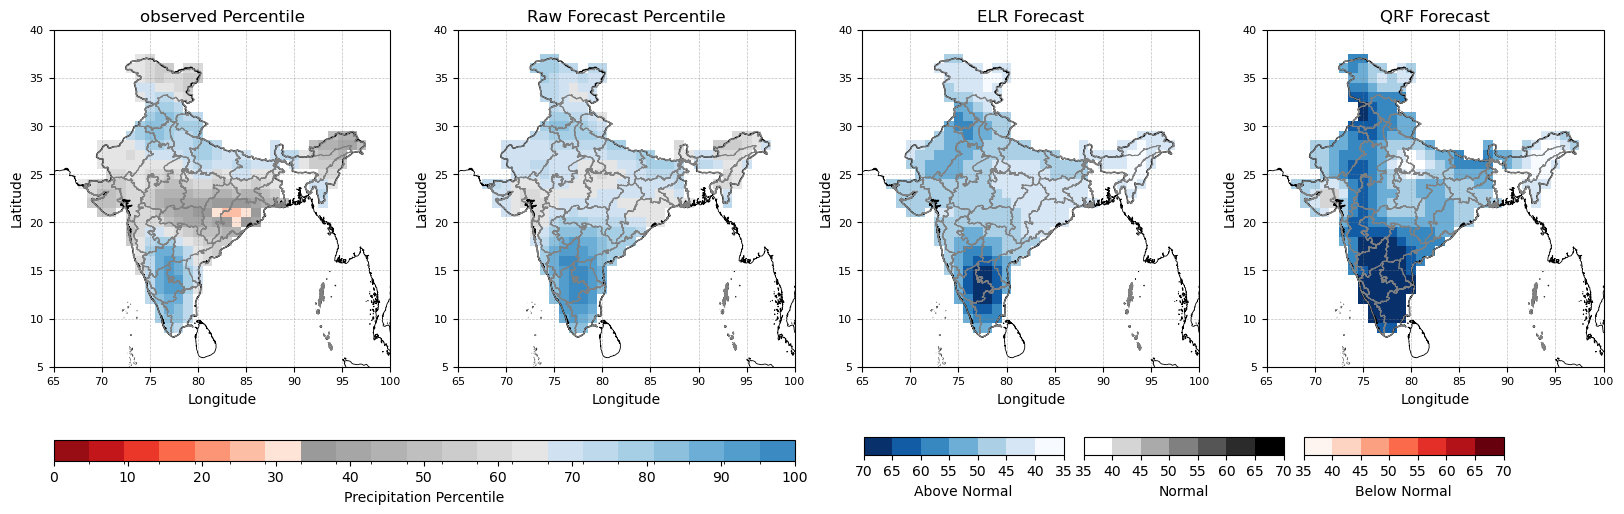

In [116]:
Y = data_13.coords["Y"]
X = data_13.coords["X"]

# === 2. Custom colormap for smoothed data ===
custom_cmap = create_custom_precip_colormap_light()
# Create 21 equal percentile bins: 0–100 with steps of 5
bounds = np.linspace(0, 100, 22)
norm_cmap = mcolors.BoundaryNorm(boundaries=bounds, ncolors=custom_cmap.N)

# === 3. Discrete norm for overlays ===
levels = np.linspace(35, 70, 8)
norm2 = BoundaryNorm(levels, ncolors=256, extend='neither')

# === 4. Read shapefiles using Cartopy ===
country_shp_path = "/Users/bohar/Documents/ELR_IRI2/shapes/indian_borders.shp"
state_shp_path = "/Users/bohar/Documents/ELR_IRI2/shapes/sd_boundary.shp"

country_shape = list(shpreader.Reader(country_shp_path).geometries())
state_shape = list(shpreader.Reader(state_shp_path).geometries())

# === 5. Create figure and GridSpec ===
fig = plt.figure(figsize=(20, 6))
gs = GridSpec(2, 4, height_ratios=[0.95, 0.05], hspace=0.2)

proj = ccrs.PlateCarree()

# === 6. First two subplots: Smoothed and Observed ===
ax1 = fig.add_subplot(gs[0, 0], projection=proj)
ax2 = fig.add_subplot(gs[0, 1], projection=proj)

c1 = ax1.pcolormesh(data_13.X, data_13.Y, smdata_13_obs, cmap=custom_cmap, norm=norm_cmap, transform=proj)
c2 = ax2.pcolormesh(data_13.X, data_13.Y, smdata_13, cmap=custom_cmap, norm=norm_cmap, transform=proj)

for ax in [ax1, ax2]:
    ax.add_geometries(country_shape, crs=proj, edgecolor='black', facecolor='none', linewidth=1, zorder=10)
    ax.add_geometries(state_shape, crs=proj, edgecolor='gray', facecolor='none', linewidth=0.7, zorder=11)
    ax.coastlines(resolution='10m', linewidth=0.6)
    ax.set_extent([data_13.X.min(), data_13.X.max(), data_13.Y.min(), data_13.Y.max()], crs=proj)
    ax.set_title("observed Percentile" if ax == ax1 else "Raw Forecast Percentile")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

# === Shared horizontal colorbar below first two plots ===
cb_ax1 = fig.add_subplot(gs[1, 0:2])
cb1 = fig.colorbar(c1, cax=cb_ax1, orientation='horizontal', ticks=np.arange(0, 101, 10))
cb1.set_label("Precipitation Percentile")

# === 7. Third subplot: SMP overlays ===
ax3 = fig.add_subplot(gs[0, 2], projection=proj)
ax3.pcolormesh(data_13.X, data_13.Y, elr_an_max, cmap="Blues", norm=norm2, transform=proj)
ax3.pcolormesh(data_13.X, data_13.Y, elr_bn_max, cmap="Reds", norm=norm2, transform=proj)
ax3.pcolormesh(data_13.X, data_13.Y, elr_n_max, cmap="gray_r", norm=norm2, transform=proj)
ax3.set_title("ELR Forecast")
ax3.set_xlabel("Longitude")
ax3.set_ylabel("Latitude")

# === 8. Fourth subplot: ELR overlays ===
ax4 = fig.add_subplot(gs[0, 3], projection=proj)
c4 = ax4.pcolormesh(data_13.X, data_13.Y, smp_an_max, cmap="Blues", norm=norm2, transform=proj)
c5 = ax4.pcolormesh(data_13.X, data_13.Y, smp_bn_max, cmap="Reds", norm=norm2, transform=proj)
c6 = ax4.pcolormesh(data_13.X, data_13.Y, smp_n_max, cmap="gray_r", norm=norm2, transform=proj)
ax4.set_title("QRF Forecast")
ax4.set_xlabel("Longitude")
ax4.set_ylabel("Latitude")

# Add borders to last two
for ax in [ax3, ax4]:
    ax.add_geometries(country_shape, crs=proj, edgecolor='black', facecolor='none', linewidth=1, zorder=10)
    ax.add_geometries(state_shape, crs=proj, edgecolor='gray', facecolor='none', linewidth=0.7, zorder=11)
    ax.coastlines(resolution='10m', linewidth=0.6)
    ax.set_extent([data_13.X.min(), data_13.X.max(), data_13.Y.min(), data_13.Y.max()], crs=proj)

# Compute nicely rounded tick values
min_longitude, max_longitude = data_13.X.min().item(), data_13.X.max().item()
min_latitude, max_latitude = data_13.Y.min().item(), data_13.Y.max().item()

longitude_ticks = np.arange(np.floor(min_longitude / 5) * 5, np.ceil(max_longitude / 5) * 5 + 1, 5)
latitude_ticks = np.arange(np.floor(min_latitude / 5) * 5, np.ceil(max_latitude / 5) * 5 + 1, 5)

# Apply to each subplot
for ax in [ax1, ax2, ax3, ax4]:
    ax.set_xticks(longitude_ticks, crs=ccrs.PlateCarree())
    ax.set_yticks(latitude_ticks, crs=ccrs.PlateCarree())
    ax.tick_params(labelsize=8, direction='out')
    ax.gridlines(draw_labels=False, linestyle="--", color='gray', alpha=0.5, linewidth=0.5)
    
# === 9. Horizontal colorbars for ELR overlays ===
cb_ax_blue = fig.add_axes([0.53, 0.12, 0.10, 0.03])
cb_ax_gray = fig.add_axes([0.64, 0.12, 0.10, 0.03])
cb_ax_red  = fig.add_axes([0.75, 0.12, 0.10, 0.03])

cb_blue = fig.colorbar(c4, cax=cb_ax_blue, orientation='horizontal', ticks=levels)
cb_gray = fig.colorbar(c6, cax=cb_ax_gray, orientation='horizontal', ticks=levels)
cb_red  = fig.colorbar(c5, cax=cb_ax_red, orientation='horizontal', ticks=levels)

cb_ax_blue.invert_xaxis()
cb_blue.set_label("Above Normal")
cb_gray.set_label("Normal")
cb_red.set_label("Below Normal")

plt.tight_layout()
filepath = f'/Users/bohar/Documents/abstract_papers/QRF/figures/forecat_week{weekn}_ini_number_{sample_no}_plot.png'
plt.savefig(filepath, format="png", dpi=300)
plt.show()
